# Project 2

# Question 3. Embed-and-Pool

1. Which design choices significantly affect performance?

2. Does using pretrained embeddings improve on your Project 1 classifier?

Removed 25 duplicate training examples; 3232 remain.
Removed 25 duplicate training examples; 3232 remain.
Removed 25 duplicate training examples; 3232 remain.


  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 0.294 seconds
Dataloader done! Time taken: 0.016 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.2605 | train acc: 0.4398 | val loss: 1.2133 | val acc: 0.4405
Epoch 02 | train loss: 1.1506 | train acc: 0.5188 | val loss: 1.0938 | val acc: 0.5394
Epoch 03 | train loss: 1.0088 | train acc: 0.6043 | val loss: 0.9664 | val acc: 0.5981
Epoch 04 | train loss: 0.9308 | train acc: 0.6371 | val loss: 0.9072 | val acc: 0.6213
Epoch 05 | train loss: 0.9068 | train acc: 0.6429 | val loss: 0.8900 | val acc: 0.6399
Epoch 06 | train loss: 0.8914 | train acc: 0.6518 | val loss: 0.8783 | val acc: 0.6414
Epoch 07 | train loss: 0.8856 | train acc: 0.6511 | val loss: 0.8743 | val acc: 0.6383
Epoch 08 | train loss: 0.8839 | train acc: 0.6491 | val loss: 0.8698 | val acc: 0.6445
Epoch 09 | train loss: 0.8726 | train acc: 0.6561 | val loss: 0.8777 | val acc: 0.6321
Epoch 10 | train loss: 0.8922 | train acc: 0.6472 | val loss: 0.8708 | val acc: 0.6445
Epoch 11 | train loss: 0.8688 | train acc: 0.6584 | val loss: 0.8708 | val acc: 0.6507
Epoch 12 | train loss: 0.8627 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

... (63 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.2548 | train acc: 0.4401 | val loss: 1.1998 | val acc: 0.4861
Epoch 02 | train loss: 1.1557 | train acc: 0.5097 | val loss: 1.0847 | val acc: 0.6006
Epoch 03 | train loss: 1.0589 | train acc: 0.5797 | val loss: 0.9955 | val acc: 0.6254
Epoch 04 | train loss: 1.0023 | train acc: 0.5916 | val loss: 0.9561 | val acc: 0.6130
Epoch 05 | train loss: 0.9808 | train acc: 0.5947 | val loss: 0.9387 | val acc: 0.6161
Epoch 06 | train loss: 0.9591 | train acc: 0.6098 | val loss: 0.9238 | val acc: 0.6238
Epoch 07 | train loss: 0.9475 | train acc: 0.6245 | val loss: 0.9139 | val acc: 0.6254
Epoch 08 | train loss: 0.9451 | train acc: 0.6098 | val loss: 0.9198 | val acc: 0.6254
Epoch 09 | train loss: 0.9415 | train acc: 0.6187 | val loss: 0.9164 | val acc: 0.6347
Epoch 10 | train loss: 0.9365 | train acc: 0.6152 | val loss: 0.9135 | val acc: 0.6238
Epoch 11 | train loss: 0.9407 | train acc: 0.6148 | val loss: 0.9121 | val acc: 0.6300
Epoch 12 | train loss: 0.9272 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.2834 | train acc: 0.4022 | val loss: 1.2174 | val acc: 0.4226
Epoch 02 | train loss: 1.1735 | train acc: 0.4822 | val loss: 1.1212 | val acc: 0.5557
Epoch 03 | train loss: 1.0728 | train acc: 0.5785 | val loss: 1.0310 | val acc: 0.5929
Epoch 04 | train loss: 0.9937 | train acc: 0.6098 | val loss: 0.9879 | val acc: 0.6006
Epoch 05 | train loss: 0.9685 | train acc: 0.6075 | val loss: 0.9745 | val acc: 0.6053
Epoch 06 | train loss: 0.9499 | train acc: 0.6218 | val loss: 0.9673 | val acc: 0.6037
Epoch 07 | train loss: 0.9399 | train acc: 0.6218 | val loss: 0.9657 | val acc: 0.6099
Epoch 08 | train loss: 0.9373 | train acc: 0.6261 | val loss: 0.9647 | val acc: 0.6068
Epoch 09 | train loss: 0.9239 | train acc: 0.6284 | val loss: 0.9568 | val acc: 0.5991
Epoch 10 | train loss: 0.9292 | train acc: 0.6311 | val loss: 0.9589 | val acc: 0.6037
Epoch 11 | train loss: 0.9277 | train acc: 0.6338 | val loss: 0.9548 | val acc: 0.6068
Epoch 12 | train loss: 0.9113 | train acc: 

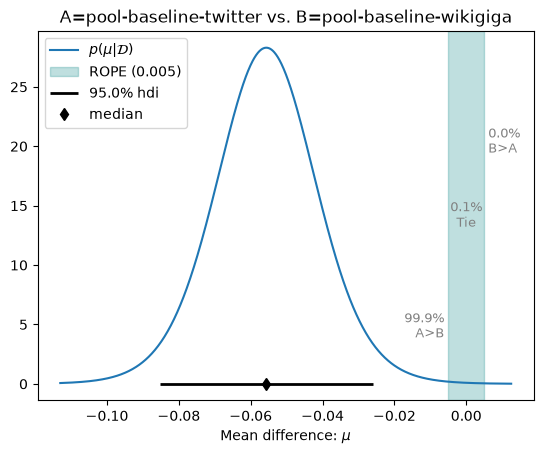

In [8]:
seeds = [0, 3, 5]
num_folds = 5

folds_by_seed = {}
for seed in seeds:
    folds_by_seed[seed], emotion_outcome_space = load_folds(k = num_folds, seed = seed)

regressor_kwargs = {"hidden_size1": 50, "hidden_size2": 50, "dropout": 0.1}
optimiser_kwargs = {"learning_rate": 1e-3, "weight_decay": 1e-4, "batch_size": 64, "num_epochs": 20}
device = "cpu"

my_classifiers = {}
for option in ["twitter", "wikigiga"]:
    option_model = load_embeddings(option)
    option_tokeniser = create_tokenizer(option_model, lowercase = True, remove_punct = True, remove_stopwords = True)
    name = f"pool-baseline-{option}"
    my_classifiers[name] = []
    for seed in seeds:
        my_classifiers[name].append(run_cross_validation(
            name, folds_by_seed[seed], emotion_outcome_space, option_tokeniser, option_model,
            "embed-and-pool", {"freeze_embeddings": True, "average_pool": True},
            regressor_kwargs, optimiser_kwargs, seed = seed, device = device))

compare_all_pairs({name: my_classifiers[name] for name in ["pool-baseline-twitter", "pool-baseline-wikigiga"]},
                  rope_size = 0.005, plot = True, runs = len(seeds))

In [9]:
chosen_embedding = "twitter"

embedding_model = load_embeddings(chosen_embedding)
pool_tokeniser = create_tokenizer(embedding_model, lowercase = True, remove_punct = True, remove_stopwords = True)
full_tokeniser = create_tokenizer(embedding_model, lowercase = True, remove_punct = False, remove_stopwords = False)

my_classifiers["pool-baseline"] = my_classifiers.pop(f"pool-baseline-{chosen_embedding}")

In [10]:
pool = {"freeze_embeddings": True, "average_pool": True}

q3_designs = {
    "pool-trainable": (pool_tokeniser, {**pool, "freeze_embeddings": False}, regressor_kwargs, optimiser_kwargs),
    "pool-sum": (pool_tokeniser, {**pool, "average_pool": False}, regressor_kwargs, optimiser_kwargs),
    "pool-keep-punct-stop": (full_tokeniser, pool, regressor_kwargs, optimiser_kwargs),
    "pool-hidden100": (pool_tokeniser, pool, {**regressor_kwargs, "hidden_size1": 100, "hidden_size2": 100}, optimiser_kwargs),
    "pool-dropout05": (pool_tokeniser, pool, {**regressor_kwargs, "dropout": 0.5}, optimiser_kwargs),
    "pool-lr3e-4": (pool_tokeniser, pool, regressor_kwargs, {**optimiser_kwargs, "learning_rate": 3e-4}),
}

for name, (tokeniser, encoder_kwargs, design_regressor, design_optimiser) in q3_designs.items():
    my_classifiers[name] = []
    for seed in seeds:
        my_classifiers[name].append(run_cross_validation(
            name = name, folds = folds_by_seed[seed], emotion_outcome_space = emotion_outcome_space, tokeniser = tokeniser, embedding_model = embedding_model,
            encoder_type = "embed-and-pool", encoder_kwargs = encoder_kwargs, regressor_kwargs = design_regressor, optimiser_kwargs = design_optimiser, seed = seed, device = device))

  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 0.359 seconds
Dataloader done! Time taken: 0.013 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.2594 | train acc: 0.4402 | val loss: 1.2098 | val acc: 0.4359
Epoch 02 | train loss: 1.1331 | train acc: 0.5342 | val loss: 1.0664 | val acc: 0.5595
Epoch 03 | train loss: 0.9352 | train acc: 0.6445 | val loss: 0.9016 | val acc: 0.6399
Epoch 04 | train loss: 0.7834 | train acc: 0.7021 | val loss: 0.8186 | val acc: 0.6801
Epoch 05 | train loss: 0.6884 | train acc: 0.7516 | val loss: 0.7818 | val acc: 0.6909
Epoch 06 | train loss: 0.6090 | train acc: 0.7834 | val loss: 0.7631 | val acc: 0.7048
Epoch 07 | train loss: 0.5402 | train acc: 0.8054 | val loss: 0.7517 | val acc: 0.7218
Epoch 08 | train loss: 0.4859 | train acc: 0.8236 | val loss: 0.7434 | val acc: 0.7280
Epoch 09 | train loss: 0.4271 | train acc: 0.8487 | val loss: 0.7530 | val acc: 0.7202
Epoch 10 | train loss: 0.3962 | train acc: 0.8627 | val loss: 0.7583 | val acc: 0.7218
Epoch 11 | train loss: 0.3284 | train acc: 0.8897 | val loss: 0.7692 | val acc: 0.7388
Epoch 12 | train loss: 0.2759 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.2726 | train acc: 0.4066 | val loss: 1.1711 | val acc: 0.4575
Epoch 02 | train loss: 1.1299 | train acc: 0.5311 | val loss: 0.9984 | val acc: 0.6244
Epoch 03 | train loss: 0.9472 | train acc: 0.6236 | val loss: 0.8554 | val acc: 0.6785
Epoch 04 | train loss: 0.7906 | train acc: 0.7006 | val loss: 0.7934 | val acc: 0.6955
Epoch 05 | train loss: 0.6895 | train acc: 0.7412 | val loss: 0.7764 | val acc: 0.7048
Epoch 06 | train loss: 0.6020 | train acc: 0.7741 | val loss: 0.7751 | val acc: 0.7110
Epoch 07 | train loss: 0.5347 | train acc: 0.7992 | val loss: 0.7830 | val acc: 0.7156
Epoch 08 | train loss: 0.4714 | train acc: 0.8325 | val loss: 0.7991 | val acc: 0.7079
Epoch 09 | train loss: 0.4104 | train acc: 0.8515 | val loss: 0.8108 | val acc: 0.7172
Epoch 10 | train loss: 0.3534 | train acc: 0.8839 | val loss: 0.8505 | val acc: 0.7156
Epoch 11 | train loss: 0.3149 | train acc: 0.8921 | val loss: 0.8741 | val acc: 0.7125
Epoch 12 | train loss: 0.2764 | train acc: 

... (206 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3253 | train acc: 0.3515 | val loss: 1.2697 | val acc: 0.4365
Epoch 02 | train loss: 1.2563 | train acc: 0.4370 | val loss: 1.2307 | val acc: 0.4334
Epoch 03 | train loss: 1.2306 | train acc: 0.4366 | val loss: 1.2053 | val acc: 0.4350
Epoch 04 | train loss: 1.2041 | train acc: 0.4555 | val loss: 1.1723 | val acc: 0.4489
Epoch 05 | train loss: 1.1673 | train acc: 0.4838 | val loss: 1.1299 | val acc: 0.5046
Epoch 06 | train loss: 1.1176 | train acc: 0.5325 | val loss: 1.0788 | val acc: 0.5511
Epoch 07 | train loss: 1.0652 | train acc: 0.5708 | val loss: 1.0325 | val acc: 0.5929
Epoch 08 | train loss: 1.0228 | train acc: 0.5932 | val loss: 0.9940 | val acc: 0.6176
Epoch 09 | train loss: 0.9875 | train acc: 0.6009 | val loss: 0.9624 | val acc: 0.6254
Epoch 10 | train loss: 0.9535 | train acc: 0.6214 | val loss: 0.9377 | val acc: 0.6347
Epoch 11 | train loss: 0.9367 | train acc: 0.6218 | val loss: 0.9231 | val acc: 0.6563
Epoch 12 | train loss: 0.9265 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3389 | train acc: 0.3658 | val loss: 1.2788 | val acc: 0.4180
Epoch 02 | train loss: 1.2540 | train acc: 0.4404 | val loss: 1.2307 | val acc: 0.4180
Epoch 03 | train loss: 1.2202 | train acc: 0.4513 | val loss: 1.2020 | val acc: 0.4241
Epoch 04 | train loss: 1.1844 | train acc: 0.4787 | val loss: 1.1653 | val acc: 0.4582
Epoch 05 | train loss: 1.1434 | train acc: 0.5112 | val loss: 1.1242 | val acc: 0.5186
Epoch 06 | train loss: 1.0915 | train acc: 0.5572 | val loss: 1.0779 | val acc: 0.5526
Epoch 07 | train loss: 1.0434 | train acc: 0.5773 | val loss: 1.0393 | val acc: 0.5635
Epoch 08 | train loss: 1.0146 | train acc: 0.5901 | val loss: 1.0006 | val acc: 0.5991
Epoch 09 | train loss: 0.9721 | train acc: 0.6090 | val loss: 0.9739 | val acc: 0.6006
Epoch 10 | train loss: 0.9541 | train acc: 0.6191 | val loss: 0.9553 | val acc: 0.6161
Epoch 11 | train loss: 0.9252 | train acc: 0.6295 | val loss: 0.9364 | val acc: 0.6192
Epoch 12 | train loss: 0.9159 | train acc: 

# Question 4. Recurrent encoder (LSTM)

1. What design choices have meaningful impact in classification performance, if any?
2. Did you investigate the impact of data size, embedding parameters (trained or not, fixed or trainable, etc)?
3. Did you struggle with over-fitting?
4. How far can this approach go? Are you able to improve meaningfully on embed-and-pool?

In [11]:
lstm = {"freeze_embeddings": True, "hidden_size": 20, "word_dropout": 0.1}

q4_designs = {
    "lstm-baseline": (1.0, False, lstm),
    "lstm-hidden50": (1.0, False, {**lstm, "hidden_size": 50}),
    "lstm-no-word-dropout": (1.0, False, {**lstm, "word_dropout": 0.0}),
    "lstm-word-dropout-0.3": (1.0, False, {**lstm, "word_dropout": 0.3}),
    "lstm-trainable": (1.0, False, {**lstm, "freeze_embeddings": False}),
    "lstm-random-emb": (1.0, True, {**lstm, "freeze_embeddings": False}),
    "lstm-data-25": (0.25, False, lstm),
    "lstm-data-50": (0.50, False, lstm),
}

for name, (fold_fraction, use_random, encoder_kwargs) in q4_designs.items():
    my_classifiers[name] = []
    for seed in seeds:
        design_folds = folds_by_seed[seed]
        if fold_fraction < 1:
            design_folds = smaller_folds(folds = design_folds, fold_fraction = fold_fraction, seed = seed)
        design_embeddings = randomise_embeddings(embedding_model = embedding_model, seed = seed) if use_random else embedding_model
        my_classifiers[name].append(run_cross_validation(
            name = name, folds = design_folds, emotion_outcome_space = emotion_outcome_space, tokeniser = full_tokeniser, embedding_model = design_embeddings,
            encoder_type = "lstm", encoder_kwargs = encoder_kwargs, regressor_kwargs = regressor_kwargs, optimiser_kwargs = optimiser_kwargs, seed = seed, device = device))


  0%|          | 0/5 [00:00<?, ?it/s]

Tokenizing texts...
Tokenization done! Time taken: 0.436 seconds
Dataloader done! Time taken: 0.008 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3096 | train acc: 0.4012 | val loss: 1.2636 | val acc: 0.4235
Epoch 02 | train loss: 1.2373 | train acc: 0.4391 | val loss: 1.2181 | val acc: 0.4467
Epoch 03 | train loss: 1.1585 | train acc: 0.5017 | val loss: 1.1092 | val acc: 0.5394
Epoch 04 | train loss: 1.0574 | train acc: 0.5718 | val loss: 1.0414 | val acc: 0.5842
Epoch 05 | train loss: 1.0142 | train acc: 0.5834 | val loss: 0.9854 | val acc: 0.6090
Epoch 06 | train loss: 0.9794 | train acc: 0.6070 | val loss: 0.9575 | val acc: 0.6321
Epoch 07 | train loss: 0.9412 | train acc: 0.6298 | val loss: 0.9311 | val acc: 0.6244
Epoch 08 | train loss: 0.9037 | train acc: 0.6348 | val loss: 0.9183 | val acc: 0.6414
Epoch 09 | train loss: 0.8867 | train acc: 0.6456 | val loss: 0.8975 | val acc: 0.6352
Epoch 10 | train loss: 0.8578 | train acc: 0.6638 | val loss: 0.8803 | val acc: 0.6414
Epoch 11 | train loss: 0.8537 | train acc: 0.6720 | val loss: 0.8744 | val acc: 0.6476
Epoch 12 | train loss: 0.8288 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3049 | train acc: 0.4000 | val loss: 1.2343 | val acc: 0.4374
Epoch 02 | train loss: 1.2450 | train acc: 0.4321 | val loss: 1.2053 | val acc: 0.4374
Epoch 03 | train loss: 1.1891 | train acc: 0.4692 | val loss: 1.1064 | val acc: 0.5317
Epoch 04 | train loss: 1.0853 | train acc: 0.5516 | val loss: 1.0023 | val acc: 0.5997
Epoch 05 | train loss: 1.0226 | train acc: 0.5915 | val loss: 0.9475 | val acc: 0.6445
Epoch 06 | train loss: 0.9658 | train acc: 0.6255 | val loss: 0.9145 | val acc: 0.6553
Epoch 07 | train loss: 0.9240 | train acc: 0.6456 | val loss: 0.8810 | val acc: 0.6692
Epoch 08 | train loss: 0.8867 | train acc: 0.6534 | val loss: 0.8616 | val acc: 0.6785
Epoch 09 | train loss: 0.8679 | train acc: 0.6611 | val loss: 0.8391 | val acc: 0.6909
Epoch 10 | train loss: 0.8453 | train acc: 0.6704 | val loss: 0.8478 | val acc: 0.6739
Epoch 11 | train loss: 0.8318 | train acc: 0.6847 | val loss: 0.8421 | val acc: 0.6847
Epoch 12 | train loss: 0.8106 | train acc: 

... (278 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3301 | train acc: 0.3882 | val loss: 1.2673 | val acc: 0.4334
Epoch 02 | train loss: 1.2547 | train acc: 0.4370 | val loss: 1.2341 | val acc: 0.4334
Epoch 03 | train loss: 1.2268 | train acc: 0.4370 | val loss: 1.1960 | val acc: 0.4458
Epoch 04 | train loss: 1.1747 | train acc: 0.4679 | val loss: 1.1277 | val acc: 0.5031
Epoch 05 | train loss: 1.1022 | train acc: 0.5383 | val loss: 1.0792 | val acc: 0.5573
Epoch 06 | train loss: 1.0342 | train acc: 0.5824 | val loss: 1.0643 | val acc: 0.5712
Epoch 07 | train loss: 0.9918 | train acc: 0.5963 | val loss: 1.0503 | val acc: 0.5542
Epoch 08 | train loss: 0.9791 | train acc: 0.6032 | val loss: 1.0412 | val acc: 0.5511
Epoch 09 | train loss: 0.9327 | train acc: 0.6326 | val loss: 1.0230 | val acc: 0.5820
Epoch 10 | train loss: 0.9259 | train acc: 0.6303 | val loss: 1.0036 | val acc: 0.5929
Epoch 11 | train loss: 0.9091 | train acc: 0.6404 | val loss: 1.0044 | val acc: 0.5898
Epoch 12 | train loss: 0.9094 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.2935 | train acc: 0.4393 | val loss: 1.2685 | val acc: 0.4180
Epoch 02 | train loss: 1.2545 | train acc: 0.4393 | val loss: 1.2525 | val acc: 0.4180
Epoch 03 | train loss: 1.2401 | train acc: 0.4393 | val loss: 1.2445 | val acc: 0.4180
Epoch 04 | train loss: 1.2232 | train acc: 0.4385 | val loss: 1.2203 | val acc: 0.4164
Epoch 05 | train loss: 1.1795 | train acc: 0.4756 | val loss: 1.1761 | val acc: 0.4861
Epoch 06 | train loss: 1.1322 | train acc: 0.5275 | val loss: 1.1300 | val acc: 0.5108
Epoch 07 | train loss: 1.0905 | train acc: 0.5398 | val loss: 1.1293 | val acc: 0.5294
Epoch 08 | train loss: 1.0468 | train acc: 0.5746 | val loss: 1.0875 | val acc: 0.5433
Epoch 09 | train loss: 1.0297 | train acc: 0.5870 | val loss: 1.0422 | val acc: 0.5774
Epoch 10 | train loss: 0.9858 | train acc: 0.5978 | val loss: 1.0203 | val acc: 0.5913
Epoch 11 | train loss: 0.9745 | train acc: 0.6141 | val loss: 0.9960 | val acc: 0.6037
Epoch 12 | train loss: 0.9325 | train acc: 

In [15]:
import importlib
import part2.classification
importlib.reload(part2.classification)
from part2.classification import loss_curves

Tokenizing texts...
Tokenization done! Time taken: 0.408 seconds
Dataloader done! Time taken: 0.008 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3067 | train acc: 0.4062 | val loss: 1.2620 | val acc: 0.4235
Epoch 02 | train loss: 1.2237 | train acc: 0.4453 | val loss: 1.2038 | val acc: 0.4590
Epoch 03 | train loss: 1.1159 | train acc: 0.5311 | val loss: 1.0762 | val acc: 0.5827
Epoch 04 | train loss: 1.0295 | train acc: 0.5872 | val loss: 1.0214 | val acc: 0.5889
Epoch 05 | train loss: 0.9844 | train acc: 0.6058 | val loss: 0.9944 | val acc: 0.5935
Epoch 06 | train loss: 0.9466 | train acc: 0.6190 | val loss: 0.9682 | val acc: 0.6260
Epoch 07 | train loss: 0.9093 | train acc: 0.6410 | val loss: 0.9430 | val acc: 0.6414
Epoch 08 | train loss: 0.8723 | train acc: 0.6499 | val loss: 0.9078 | val acc: 0.6538
Epoch 09 | train loss: 0.8493 | train acc: 0.6631 | val loss: 0.9124 | val acc: 0.6291
Epoch 10 | train loss: 0.8236 | train acc: 0.6843 | val loss: 0.8856 | val acc: 0.6476
Epoch 11 | train loss: 0.8095 | train acc: 0.6971 | val loss: 0.8708 | val acc: 0.6615
Epoch 12 | train loss: 0.7896 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3116 | train acc: 0.4004 | val loss: 1.2653 | val acc: 0.4235
Epoch 02 | train loss: 1.2471 | train acc: 0.4356 | val loss: 1.2325 | val acc: 0.4235
Epoch 03 | train loss: 1.2008 | train acc: 0.4677 | val loss: 1.1239 | val acc: 0.5471
Epoch 04 | train loss: 1.1118 | train acc: 0.5404 | val loss: 1.0537 | val acc: 0.5827
Epoch 05 | train loss: 1.0612 | train acc: 0.5683 | val loss: 0.9901 | val acc: 0.6090
Epoch 06 | train loss: 1.0227 | train acc: 0.5903 | val loss: 0.9762 | val acc: 0.6167
Epoch 07 | train loss: 1.0022 | train acc: 0.5930 | val loss: 0.9416 | val acc: 0.6368
Epoch 08 | train loss: 0.9731 | train acc: 0.6027 | val loss: 0.9333 | val acc: 0.6275
Epoch 09 | train loss: 0.9667 | train acc: 0.6139 | val loss: 0.9367 | val acc: 0.6213
Epoch 10 | train loss: 0.9503 | train acc: 0.6228 | val loss: 0.9051 | val acc: 0.6430
Epoch 11 | train loss: 0.9439 | train acc: 0.6263 | val loss: 0.9013 | val acc: 0.6430
Epoch 12 | train loss: 0.9255 | train acc: 

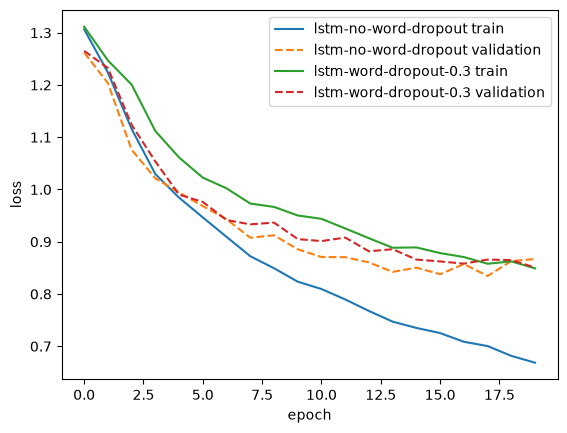

In [16]:
for name in ["lstm-no-word-dropout", "lstm-word-dropout-0.3"]:
    fold_fraction, use_random, encoder_kwargs = q4_designs[name]
    training_loss, validation_loss, best_epoch = loss_curves(
        f"{name}-curve", folds_by_seed[0][0], emotion_outcome_space, full_tokeniser, embedding_model,
        "lstm", encoder_kwargs, regressor_kwargs, optimiser_kwargs, device = device)
    plt.plot(training_loss, label = f"{name} train")
    plt.plot(validation_loss, "--", label = f"{name} validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

## Results and comparison

Macro-F1 over 3 seeds x 5 folds for every design, compared with the best model from Project 1 (tf-idf + log-linear) on the same folds.

In [20]:
p1 = pd.read_csv("../part1/results/comparison.csv")
p1_best = p1[p1["model"] == "tfidf-loglin"].sort_values(["run", "fold"])
my_classifiers["p1-tfidf-loglin"] = [
    {"accuracies": dict(zip(run_scores["fold"], run_scores["macro-F1"]))}
    for _, run_scores in p1_best.groupby("run")
]

                            mean       std  count
model                                            
pool-baseline-wikigiga  0.542157  0.020638     15
pool-baseline           0.597811  0.030097     15
pool-trainable          0.643786  0.024616     15
pool-sum                0.608742  0.027390     15
pool-keep-punct-stop    0.565020  0.023665     15
pool-hidden100          0.600271  0.028323     15
pool-dropout05          0.540808  0.038476     15
pool-lr3e-4             0.594065  0.026970     15
lstm-baseline           0.621504  0.027424     15
lstm-hidden50           0.627207  0.020228     15
lstm-no-word-dropout    0.612016  0.022579     15
lstm-word-dropout-0.3   0.614225  0.026304     15
lstm-trainable          0.574529  0.040065     15
lstm-random-emb         0.367717  0.039385     15
lstm-data-25            0.461884  0.033883     15
lstm-data-50            0.551906  0.037247     15
p1-tfidf-loglin         0.603752  0.020027     15


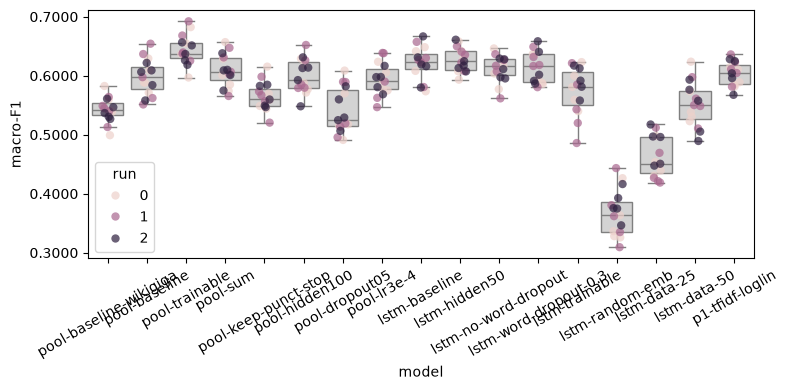

In [21]:
comparison = part1.analysis.make_data_frame(my_classifiers).rename(columns = {"accuracy": "macro-F1"})
comparison.to_csv("../part2/results/comparison.csv", index = False)
summary = comparison.groupby(by = "model", sort = False)["macro-F1"].agg(func = ["mean", "std", "count"])
print(summary.to_string())
part1.analysis.plot_box_and_points(df = comparison, metric = "macro-F1")

Tokenizing texts...
Tokenization done! Time taken: 0.435 seconds
Dataloader done! Time taken: 0.009 seconds


  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3096 | train acc: 0.4012 | val loss: 1.2636 | val acc: 0.4235
Epoch 02 | train loss: 1.2373 | train acc: 0.4391 | val loss: 1.2181 | val acc: 0.4467
Epoch 03 | train loss: 1.1585 | train acc: 0.5017 | val loss: 1.1092 | val acc: 0.5394
Epoch 04 | train loss: 1.0574 | train acc: 0.5718 | val loss: 1.0414 | val acc: 0.5842
Epoch 05 | train loss: 1.0142 | train acc: 0.5834 | val loss: 0.9854 | val acc: 0.6090
Epoch 06 | train loss: 0.9794 | train acc: 0.6070 | val loss: 0.9575 | val acc: 0.6321
Epoch 07 | train loss: 0.9412 | train acc: 0.6298 | val loss: 0.9311 | val acc: 0.6244
Epoch 08 | train loss: 0.9037 | train acc: 0.6348 | val loss: 0.9183 | val acc: 0.6414
Epoch 09 | train loss: 0.8867 | train acc: 0.6456 | val loss: 0.8975 | val acc: 0.6352
Epoch 10 | train loss: 0.8578 | train acc: 0.6638 | val loss: 0.8803 | val acc: 0.6414
Epoch 11 | train loss: 0.8537 | train acc: 0.6720 | val loss: 0.8744 | val acc: 0.6476
Epoch 12 | train loss: 0.8288 | train acc: 

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 01 | train loss: 1.3091 | train acc: 0.4012 | val loss: 1.2623 | val acc: 0.4235
Epoch 02 | train loss: 1.2314 | train acc: 0.4414 | val loss: 1.2040 | val acc: 0.4575
Epoch 03 | train loss: 1.1138 | train acc: 0.5284 | val loss: 1.0582 | val acc: 0.5811
Epoch 04 | train loss: 0.9519 | train acc: 0.6309 | val loss: 0.9834 | val acc: 0.6213
Epoch 05 | train loss: 0.8497 | train acc: 0.6611 | val loss: 0.9185 | val acc: 0.6445
Epoch 06 | train loss: 0.7528 | train acc: 0.7095 | val loss: 0.9136 | val acc: 0.6615
Epoch 07 | train loss: 0.6654 | train acc: 0.7451 | val loss: 0.9006 | val acc: 0.6491
Epoch 08 | train loss: 0.5684 | train acc: 0.7861 | val loss: 0.9417 | val acc: 0.6600
Epoch 09 | train loss: 0.5373 | train acc: 0.8027 | val loss: 0.9138 | val acc: 0.6816
Epoch 10 | train loss: 0.4476 | train acc: 0.8352 | val loss: 0.9674 | val acc: 0.6847
Epoch 11 | train loss: 0.4046 | train acc: 0.8638 | val loss: 0.9823 | val acc: 0.6816
Epoch 12 | train loss: 0.3806 | train acc: 

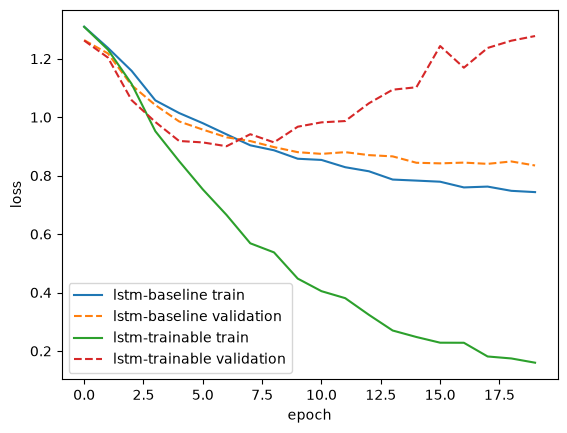

In [24]:
curve_designs = {
    "lstm-baseline": {"freeze_embeddings": True, "hidden_size": 20, "word_dropout": 0.1},
    "lstm-trainable": {"freeze_embeddings": False, "hidden_size": 20, "word_dropout": 0.1},
}

for name, encoder_kwargs in curve_designs.items():
    training_loss, validation_loss, best_epoch = loss_curves(
        f"{name}-curve", folds_by_seed[0][0], emotion_outcome_space, full_tokeniser, embedding_model,
        "lstm", encoder_kwargs, regressor_kwargs, optimiser_kwargs, device = device)
    plt.plot(training_loss, label = f"{name} train")
    plt.plot(validation_loss, "--", label = f"{name} validation")
    print(f"{name}: best epoch {best_epoch + 1}")

plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

In [22]:
rope_size = 0.005
compare_all_pairs(my_classifiers, rope_size = rope_size, plot = False, runs = len(seeds))

A=pool-baseline-wikigiga B=pool-baseline: P(A wins)=0.0003 P(Tie)=0.0010 P(B wins)=0.9987 Effect Size=4.02
A=pool-baseline-wikigiga B=pool-trainable: P(A wins)=0.0000 P(Tie)=0.0000 P(B wins)=1.0000 Effect Size=6.61
A=pool-baseline-wikigiga B=pool-sum: P(A wins)=0.0000 P(Tie)=0.0001 P(B wins)=0.9999 Effect Size=5.58
A=pool-baseline-wikigiga B=pool-keep-punct-stop: P(A wins)=0.0325 P(Tie)=0.0775 P(B wins)=0.8900 Effect Size=1.64
A=pool-baseline-wikigiga B=pool-hidden100: P(A wins)=0.0001 P(Tie)=0.0003 P(B wins)=0.9996 Effect Size=4.59
A=pool-baseline-wikigiga B=pool-dropout05: P(A wins)=0.4214 P(Tie)=0.2132 P(B wins)=0.3654 Effect Size=-0.07
A=pool-baseline-wikigiga B=pool-lr3e-4: P(A wins)=0.0003 P(Tie)=0.0009 P(B wins)=0.9988 Effect Size=4.10
A=pool-baseline-wikigiga B=lstm-baseline: P(A wins)=0.0000 P(Tie)=0.0001 P(B wins)=0.9999 Effect Size=5.41
A=pool-baseline-wikigiga B=lstm-hidden50: P(A wins)=0.0000 P(Tie)=0.0000 P(B wins)=1.0000 Effect Size=6.60
A=pool-baseline-wikigiga B=lstm-n

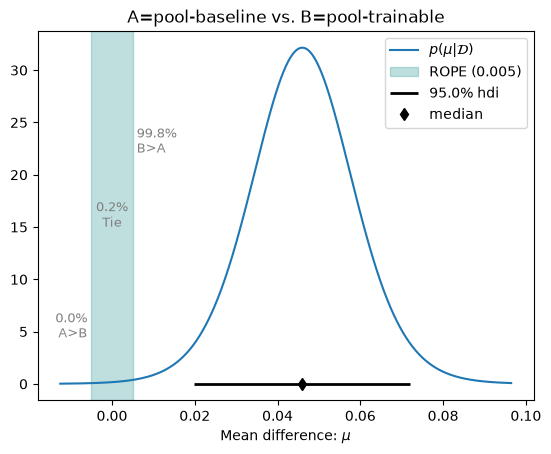

In [25]:
model_a, model_b = "pool-baseline", "pool-trainable"

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, model_a).flatten(),
    get_all_measurements_for(my_classifiers, model_b).flatten(),
    runs = len(seeds),
    names = [model_a, model_b],
)
_ = posterior.plot(rope_size)

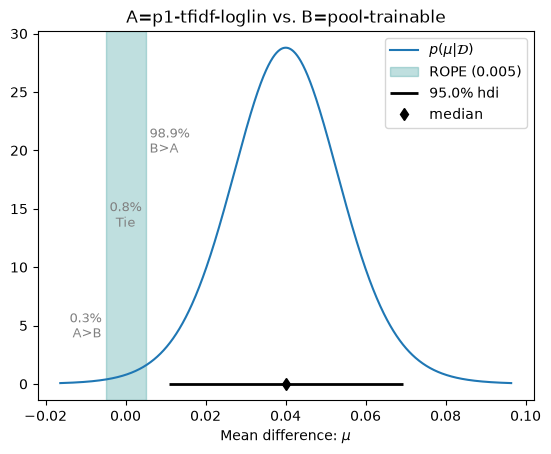

In [26]:
model_a, model_b = "p1-tfidf-loglin", "pool-trainable"

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, model_a).flatten(),
    get_all_measurements_for(my_classifiers, model_b).flatten(),
    runs = len(seeds),
    names = [model_a, model_b],
)
_ = posterior.plot(rope_size)

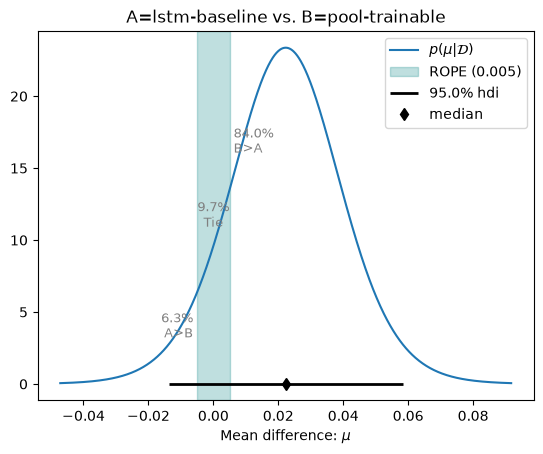

In [27]:
model_a, model_b = "lstm-baseline", "pool-trainable"

posterior = part1.analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, model_a).flatten(),
    get_all_measurements_for(my_classifiers, model_b).flatten(),
    runs = len(seeds),
    names = [model_a, model_b],
)
_ = posterior.plot(rope_size)